# Unit IV: Foundations of Data Science Programming with Python

**Syllabus:** NumPy arrays and vectors, indexing and slicing, multi-dimensional arrays, matrices (2-D arrays), PCA, matrix
subsetting `array[row_slice, col_slice]`, categorical data and pandas DataFrames (`loc`, `iloc`), category levels and
summaries, extending DataFrames, sorting, Python lists and dictionaries and their data-science applications, analysing a CSV
with lists and dictionaries, creating/indexing/slicing/reshaping arrays, vectorised operations.

Note on the project: `src/detect.py` already contains a PCA-based detector, `detect_feature_corruption_pca`, that the final
pipeline does not use (it was replaced by a cross-feature detector). Section 4.3 builds PCA from first principles and then
runs that function so the idea is exercised end to end.

In [1]:
import sys, pathlib
for _p in (pathlib.Path.cwd(), pathlib.Path.cwd() / "notebooks"):   # works from notebooks/ or the project root
    if (_p / "common.py").exists():
        sys.path.insert(0, str(_p)); break
from common import *
df = load_adult()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns (UCI Adult, natively-missing rows dropped)")

45,222 rows x 15 columns (UCI Adult, natively-missing rows dropped)


## 4.1 NumPy arrays and vectors

A **NumPy array** (`ndarray`) is a fixed-type grid of numbers stored in one block of memory. That is why it is fast and why
arithmetic applies to the whole array at once (**vectorisation**). Dimensions: 1-D = *vector*, 2-D = *matrix*, 3-D and up =
*tensor*. The attributes to know are `shape`, `ndim`, `size` and `dtype`.

In [2]:
rng = np.random.default_rng(SEED)
v = np.array([3, 1, 4, 1, 5, 9, 2, 6])
print("v =", v, "| shape", v.shape, "| ndim", v.ndim, "| size", v.size, "| dtype", v.dtype)
print("arange(0,10,3):", np.arange(0, 10, 3), "| linspace(0,1,5):", np.linspace(0, 1, 5))
print("zeros(2,3):", np.zeros((2, 3)).tolist(), "| eye(3):", np.eye(3, dtype=int).tolist())
print("random normal:", rng.normal(size=3).round(3))

print("\nIndexing and slicing a vector")
print("v[0] =", v[0], "| v[-1] =", v[-1], "| v[2:5] =", v[2:5], "| v[::2] =", v[::2], "| v[::-1] =", v[::-1])
print("boolean mask v[v > 3] =", v[v > 3], "| fancy index v[[0, 2, 4]] =", v[[0, 2, 4]])

print("\nVector operations (element-wise, no loop)")
w = np.arange(1, 9)
print("v + w =", v + w, "| v * 2 =", v * 2, "| dot(v, w) =", v @ w, "| norm(v) =", np.linalg.norm(v).round(3))
print("cumsum:", v.cumsum(), "| sorted:", np.sort(v), "| argsort (positions that sort v):", np.argsort(v), "| where v>4:", np.where(v > 4)[0])

v = [3 1 4 1 5 9 2 6] | shape (8,) | ndim 1 | size 8 | dtype int64
arange(0,10,3): [0 3 6 9] | linspace(0,1,5): [0.   0.25 0.5  0.75 1.  ]
zeros(2,3): [[0.0, 0.0, 0.0], [0.0, 0.0, 0.0]] | eye(3): [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
random normal: [ 0.305 -1.04   0.75 ]

Indexing and slicing a vector
v[0] = 3 | v[-1] = 6 | v[2:5] = [4 1 5] | v[::2] = [3 4 5 2] | v[::-1] = [6 2 9 5 1 4 1 3]
boolean mask v[v > 3] = [4 5 9 6] | fancy index v[[0, 2, 4]] = [3 4 5]

Vector operations (element-wise, no loop)
v + w = [ 4  3  7  5 10 15  9 14] | v * 2 = [ 6  2  8  2 10 18  4 12] | dot(v, w) = 162 | norm(v) = 13.153
cumsum: [ 3  4  8  9 14 23 25 31] | sorted: [1 1 2 3 4 5 6 9] | argsort (positions that sort v): [1 3 6 0 2 4 7 5] | where v>4: [4 5 7]


**Multi-dimensional arrays.** Our 6 numeric attributes for 45,222 people make a **2-D array** (rows = people, columns =
attributes). `axis=0` runs *down the rows* (one result per column); `axis=1` runs *across the columns* (one result per row).
A **3-D array** adds a grouping dimension: here 500 batches of 90 people with 6 attributes each.

In [3]:
A = df[NUMERIC].to_numpy(dtype=float)
ix = {name: i for i, name in enumerate(NUMERIC)}          # a dict: attribute name -> column index
print("A shape", A.shape, "| ndim", A.ndim, "| dtype", A.dtype, "| column positions:", ix)
print("first person:", A[0], "| age column (first 5):", A[:5, ix["age"]], "| A[0, 1] =", A[0, 1])
print("column means (axis=0):", A.mean(axis=0).round(1))
print("row sums of first 3 people (axis=1):", A[:3].sum(axis=1))

B = A[:45000].reshape(500, 90, 6)                          # 500 batches x 90 people x 6 attributes
print("\n3-D array B:", B.shape, "-> mean age of each batch (first 5):", B[:5, :, ix["age"]].mean(axis=1).round(2))
print("mean over batches of the batch means:", B.mean(axis=1).mean(axis=0).round(1), "(same as A's means on the first 45,000 rows)")

print("\nReshaping:", A[:6].reshape(3, 12).shape, "| ravel:", A[:2].ravel().shape, "| transpose:", A[:4].T.shape,
      "| stack columns:", np.column_stack([A[:, 0], A[:, 5]]).shape, "| concatenate rows:", np.concatenate([A[:2], A[-2:]]).shape)

A shape (45222, 6) | ndim 2 | dtype float64 | column positions: {'age': 0, 'fnlwgt': 1, 'education-num': 2, 'capital-gain': 3, 'capital-loss': 4, 'hours-per-week': 5}
first person: [2.50000e+01 2.26802e+05 7.00000e+00 0.00000e+00 0.00000e+00 4.00000e+01] | age column (first 5): [25. 38. 28. 44. 34.] | A[0, 1] = 226802.0
column means (axis=0): [3.850000e+01 1.897347e+05 1.010000e+01 1.101400e+03 8.860000e+01
 4.090000e+01]
row sums of first 3 people (axis=1): [226874.  89911. 337031.]

3-D array B: (500, 90, 6) -> mean age of each batch (first 5): [36.9  36.39 37.72 37.54 36.07]
mean over batches of the batch means: [3.850000e+01 1.897269e+05 1.010000e+01 1.101500e+03 8.870000e+01
 4.090000e+01] (same as A's means on the first 45,000 rows)

Reshaping: (3, 12) | ravel: (12,) | transpose: (6, 4) | stack columns: (45222, 2) | concatenate rows: (4, 6)


**Vectorised operations and broadcasting.** A Python `for` loop handles one number at a time through the interpreter; a
NumPy operation runs one compiled loop over the whole array. **Broadcasting** lets arrays of different shapes combine: a
`(45222, 6)` array minus a `(6,)` vector subtracts that vector from *every row*.

In [4]:
import time

x = rng.random(1_000_000)
t0 = time.perf_counter(); loop_result = sum(val * val for val in x.tolist()); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); vec_result = (x * x).sum();                          t_vec = time.perf_counter() - t0
print(f"sum of squares of 1,000,000 numbers: loop {t_loop * 1000:.1f} ms | vectorised {t_vec * 1000:.2f} ms "
      f"-> about {t_loop / t_vec:.0f}x faster | same answer: {np.isclose(loop_result, vec_result)}")

# broadcasting: z-score every column at once with no loop
Z = (A - A.mean(axis=0)) / A.std(axis=0)          # (45222, 6) - (6,) / (6,)
print("\nbroadcasting shapes:", A.shape, "-", A.mean(axis=0).shape, "->", Z.shape)
print("column means after z-scoring ~ 0:", Z.mean(axis=0).round(8), "| column stds = 1:", Z.std(axis=0).round(3))
from sklearn.preprocessing import StandardScaler
print("identical to sklearn StandardScaler:", np.allclose(Z, StandardScaler().fit_transform(A)))

sum of squares of 1,000,000 numbers: loop 28.2 ms | vectorised 0.76 ms -> about 37x faster | same answer: True

broadcasting shapes: (45222, 6) - (6,) -> (45222, 6)
column means after z-scoring ~ 0: [-0.  0.  0. -0.  0.  0.] | column stds = 1: [1. 1. 1. 1. 1. 1.]
identical to sklearn StandardScaler: True


## 4.2 Matrices and matrix subsetting

A **matrix** is a 2-D array. Key operations: transpose `M.T`, matrix product `M @ N` (not element-wise `*`), determinant,
inverse, rank, and solving linear systems. These are the building blocks of regression (Unit VI) and PCA (4.3).

In [5]:
M = np.array([[2., 1.], [1., 3.]])
b = np.array([5., 10.])
print("M =", M.tolist(), "| M.T =", M.T.tolist(), "| M @ M =", (M @ M).tolist(), "| element-wise M * M =", (M * M).tolist())
print("det(M) =", round(np.linalg.det(M), 3), "| rank =", np.linalg.matrix_rank(M), "| inverse =", np.linalg.inv(M).round(3).tolist())
print("M @ inv(M) is the identity:", np.allclose(M @ np.linalg.inv(M), np.eye(2)))
sol = np.linalg.solve(M, b)
print(f"solve M x = b  ->  x = {sol.round(3)}  (check M @ x = {M @ sol})")
vals, vecs = np.linalg.eigh(M)
print("eigenvalues:", vals.round(3), "| M @ v = lambda * v holds:", np.allclose(M @ vecs[:, 1], vals[1] * vecs[:, 1]))

M = [[2.0, 1.0], [1.0, 3.0]] | M.T = [[2.0, 1.0], [1.0, 3.0]] | M @ M = [[5.0, 5.0], [5.0, 10.0]] | element-wise M * M = [[4.0, 1.0], [1.0, 9.0]]
det(M) = 5.0 | rank = 2 | inverse = [[0.6, -0.2], [-0.2, 0.4]]
M @ inv(M) is the identity: True
solve M x = b  ->  x = [1. 3.]  (check M @ x = [ 5. 10.])
eigenvalues: [1.382 3.618] | M @ v = lambda * v holds: True


**Matrix subsetting: `array[row_slice, col_slice]`.** The first index selects rows, the second selects columns. Each can be
a single position, a slice `a:b:step`, a list of positions, or a boolean mask.

In [6]:
age, hours = ix["age"], ix["hours-per-week"]
rows, cols = slice(0, 5), slice(0, 3)
print("A[rows, cols]  (first 5 people, first 3 attributes):\n", A[rows, cols])
print("\nA[::10000, [age, hours]]  (every 10,000th person, age and hours):\n", A[::10000][:, [age, hours]])
print("\nnp.ix_ picks the rows x columns *grid*:\n", A[np.ix_([0, 2, 4], [age, hours])])

mask = A[:, hours] > 90
print(f"\nboolean subsetting A[A[:, hours] > 90][:, [age, hours]] -> {mask.sum()} people working over 90 h/week; first rows:\n",
      A[mask][:, [age, hours]][:4])
print("\nshapes -> A[0]:", A[0].shape, "| A[:, 0]:", A[:, 0].shape, "| A[:5, :3]:", A[:5, :3].shape, "| A[:, [0]]:", A[:, [0]].shape, "(a column kept as a matrix)")

A[rows, cols]  (first 5 people, first 3 attributes):
 [[2.50000e+01 2.26802e+05 7.00000e+00]
 [3.80000e+01 8.98140e+04 9.00000e+00]
 [2.80000e+01 3.36951e+05 1.20000e+01]
 [4.40000e+01 1.60323e+05 1.00000e+01]
 [3.40000e+01 1.98693e+05 6.00000e+00]]

A[::10000, [age, hours]]  (every 10,000th person, age and hours):
 [[25. 40.]
 [41. 40.]
 [63. 25.]
 [19. 40.]
 [26. 45.]]

np.ix_ picks the rows x columns *grid*:
 [[25. 40.]
 [28. 40.]
 [34. 30.]]

boolean subsetting A[A[:, hours] > 90][:, [age, hours]] -> 157 people working over 90 h/week; first rows:
 [[29. 99.]
 [35. 96.]
 [37. 99.]
 [31. 99.]]

shapes -> A[0]: (6,) | A[:, 0]: (45222,) | A[:5, :3]: (5, 3) | A[:, [0]]: (45222, 1) (a column kept as a matrix)


**The covariance and correlation matrices.** For standardised data `Z`, the matrix product `Z.T @ Z / n` *is* the
correlation matrix: entry (i, j) says how attribute i and j move together. We compute it with matrix algebra and confirm
that it equals what pandas gives:

In [7]:
n = Z.shape[0]
corr_matrix = Z.T @ Z / n          # divide by n because Z was standardised with the population std (ddof=0)
print("by matrix product == np.corrcoef:", np.allclose(corr_matrix, np.corrcoef(A, rowvar=False)),
      "| == pandas .corr():", np.allclose(corr_matrix, df[NUMERIC].corr().to_numpy()))
pd.DataFrame(corr_matrix, index=NUMERIC, columns=NUMERIC).round(2)

by matrix product == np.corrcoef: True | == pandas .corr(): True


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
age,1.00,-0.08,0.04,0.08,0.06,0.10
fnlwgt,-0.08,1.00,-0.04,-0.00,-0.00,-0.02
education-num,0.04,-0.04,1.00,0.13,0.08,0.15
capital-gain,0.08,-0.00,0.13,1.00,-0.03,0.08
capital-loss,0.06,-0.00,0.08,-0.03,1.00,0.05
hours-per-week,0.10,-0.02,0.15,0.08,0.05,1.00


## 4.3 Principal Component Analysis (PCA)

PCA finds **new axes** (principal components) that are straight-line combinations of the original attributes, ordered so that
the first axis captures the *most variance*, the second the most of what is left, and so on, with all axes at right angles.
Uses: **dimensionality reduction**, **visualising** many attributes in 2-D, **removing correlated redundancy**, and
**anomaly detection** (rows that the leading components cannot reconstruct are unusual: the project's detector).

**Recipe:** (1) standardise the columns, (2) form the covariance matrix, (3) take its **eigenvectors** (the axes) and
**eigenvalues** (the variance along each axis), (4) sort by eigenvalue, (5) project: `scores = Z @ eigenvectors`.
We do this with the matrix tools from 4.2 and compare with scikit-learn.

explained variance ratio, by hand : [0.2215 0.1724 0.1697 0.1566 0.1477 0.1321]
explained variance ratio, sklearn : [0.2215 0.1724 0.1697 0.1566 0.1477 0.1321]
same axes up to sign: True


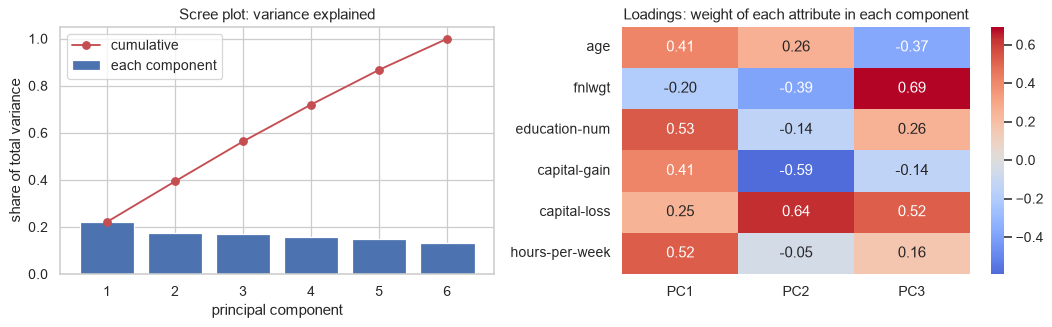

In [8]:
from sklearn.decomposition import PCA

cov = np.cov(Z, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov)
order = np.argsort(eigvals)[::-1]                    # eigh returns ascending order; we want the largest first
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
scores = Z @ eigvecs                                  # coordinates of every person on the new axes
explained = eigvals / eigvals.sum()

pca = PCA().fit(Z)
print("explained variance ratio, by hand :", explained.round(4))
print("explained variance ratio, sklearn :", pca.explained_variance_ratio_.round(4))
print("same axes up to sign:", np.allclose(np.abs(eigvecs.T), np.abs(pca.components_), atol=1e-6))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(range(1, 7), explained, label="each component"); axes[0].plot(range(1, 7), explained.cumsum(), "o-r", label="cumulative")
axes[0].set(title="Scree plot: variance explained", xlabel="principal component", ylabel="share of total variance"); axes[0].legend()
load = pd.DataFrame(eigvecs[:, :3], index=NUMERIC, columns=["PC1", "PC2", "PC3"])
sns.heatmap(load, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1]); axes[1].set_title("Loadings: weight of each attribute in each component")
plt.show()

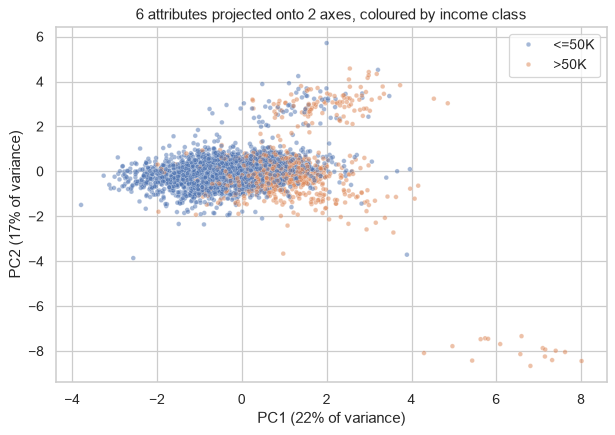

,components kept,variance retained,reconstruction error (mean squared)
0,1,0.2215,0.7785
1,2,0.3939,0.6061
2,3,0.5636,0.4364
3,4,0.7202,0.2798
4,5,0.8679,0.1321
5,6,1.0000,0.0000


In [9]:
idx = rng.choice(len(df), 4000, replace=False)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=scores[idx, 0], y=scores[idx, 1], hue=df[TARGET].to_numpy()[idx], alpha=.5, s=14)
plt.xlabel(f"PC1 ({explained[0]:.0%} of variance)"); plt.ylabel(f"PC2 ({explained[1]:.0%} of variance)"); plt.title("6 attributes projected onto 2 axes, coloured by income class")
plt.show()

rec = []
for k in range(1, 7):                                   # reconstruct the data from only the first k components
    Zk = scores[:, :k] @ eigvecs[:, :k].T
    rec.append({"components kept": k, "variance retained": explained[:k].sum(), "reconstruction error (mean squared)": ((Z - Zk) ** 2).mean()})
pd.DataFrame(rec).round(4)

**Reading it.** The scree plot shows how many components are worth keeping (the cumulative line tells how much of the
information the first *k* retain). The loadings say *what each axis means*: the weight of each attribute in it. The
reconstruction-error table shows the other side: with all 6 components the error is 0 (nothing lost); with fewer, the error is
exactly the variance thrown away. **Because the numeric attributes here are only weakly correlated** (see the correlation
matrix above), PCA cannot compress them much (no component dominates), which is an honest result: PCA helps only when
attributes are redundant.

**The project's PCA detector.** `detect_feature_corruption_pca` (in `src/detect.py`, not part of the final audit) encodes
*all* attributes (one-hot + scaled numerics), keeps enough components for 95% of the variance, reconstructs every row and
flags rows whose reconstruction error is more than `mean + 3 x std`. On this **clean** data any flag is a false alarm, so the
flagged share is that detector's *false-positive floor*:

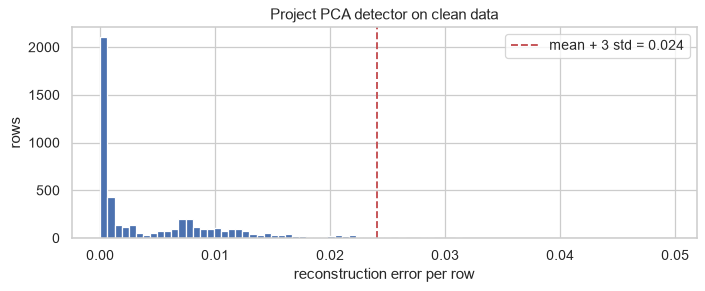

Flagged 73 of 5,000 clean rows (1.5%); every one of these is a false alarm.


In [10]:
from detect import detect_feature_corruption_pca

Xs = df.drop(columns=TARGET).sample(5000, random_state=SEED)
res = detect_feature_corruption_pca(Xs, variance_to_keep=0.95, k=3.0, seed=SEED)
err = res.extra["reconstruction_error"]
thr = err.mean() + 3 * err.std()
plt.figure(figsize=(8, 3.4))
plt.hist(err, bins=80); plt.axvline(thr, color="r", ls="--", label=f"mean + 3 std = {thr:.3f}")
plt.xlabel("reconstruction error per row"); plt.ylabel("rows"); plt.title("Project PCA detector on clean data"); plt.legend()
plt.show()
print(f"Flagged {res.row_mask.sum()} of {len(Xs):,} clean rows ({res.rate:.1%}); every one of these is a false alarm.")

## 4.4 Pandas DataFrames: `loc`, `iloc`, categories, extending, sorting

A **Series** is one labelled column; a **DataFrame** is a table of Series sharing a row index. There are two ways to select:

| | by **label** | by **position** |
|---|---|---|
| rows and/or columns | `df.loc[row_label, col_label]` | `df.iloc[row_pos, col_pos]` |
| single cell, fast | `df.at[row_label, col]` | `df.iat[row_pos, col_pos]` |
| slice end | **inclusive** (`loc[2:4]` = 2,3,4) | **exclusive** (`iloc[2:4]` = 2,3) |

The two differ whenever the row index is not 0..n-1, which is common after filtering or sampling (the research code's
`three_way_split` keeps the original row labels for exactly that reason):

In [11]:
s = df.sample(5, random_state=1)
print("A random sample keeps its original row labels:", s.index.tolist())
print("\ns.iloc[0]  (first row by position):", s.iloc[0][["age", "sex", "occupation"]].to_dict())
label = s.index[0]
print(f"s.loc[{label}] (row with label {label})     :", s.loc[label, ["age", "sex", "occupation"]].to_dict())
try:
    s.loc[0]
except KeyError:
    print("\ns.loc[0] -> KeyError: no row is *labelled* 0 here, although s.iloc[0] (the first row) exists")
print("\ns.iloc[1:3, 0:2] (rows 1-2, columns 0-1, end exclusive):\n", s.iloc[1:3, 0:2])
print("\ns.loc[:, 'age':'education'] (columns by label range, end INCLUSIVE):", s.loc[:, "age":"education"].columns.tolist())
print("\nscalar access  df.at[10, 'age'] =", df.at[10, "age"], "| df.iat[10, 0] =", df.iat[10, 0])
print("\nboolean selection with loc:", df.loc[(df["age"] > 80) & (df["sex"] == "Female"), ["age", "occupation", TARGET]].head(3).to_dict("records"))
print("same with query():", len(df.query("age > 80 and sex == 'Female'")), "rows")

A random sample keeps its original row labels: [38980, 29384, 9956, 14658, 37645]

s.iloc[0]  (first row by position): {'age': 64, 'sex': 'Female', 'occupation': 'Exec-managerial'}
s.loc[38980] (row with label 38980)     : {'age': 64, 'sex': 'Female', 'occupation': 'Exec-managerial'}

s.loc[0] -> KeyError: no row is *labelled* 0 here, although s.iloc[0] (the first row) exists

s.iloc[1:3, 0:2] (rows 1-2, columns 0-1, end exclusive):
        age workclass
29384   56   Private
9956    36   Private

s.loc[:, 'age':'education'] (columns by label range, end INCLUSIVE): ['age', 'workclass', 'fnlwgt', 'education']

scalar access  df.at[10, 'age'] = 26 | df.iat[10, 0] = 26

boolean selection with loc: [{'age': 81, 'occupation': 'Machine-op-inspct', 'class': '<=50K'}, {'age': 82, 'occupation': 'Exec-managerial', 'class': '<=50K'}, {'age': 81, 'occupation': 'Sales', 'class': '<=50K'}]
same with query(): 35 rows


**Categorical data.** A `category` column stores each distinct text once plus an integer *code* per row: less memory, and it
can carry an **order**. `.cat.categories` lists the levels, `.cat.codes` the integer codes. Summaries respect the levels.

In [12]:
d = df.copy()
edu_order = d.groupby("education", observed=True)["education-num"].first().sort_values().index.astype(str).tolist()

print("education levels (alphabetical by default):", d["education"].cat.categories.tolist()[:6], "...")
print("first rows as integer codes:", d["education"].cat.codes.head(5).tolist(), "<->", d["education"].head(5).astype(str).tolist())

d["education"] = d["education"].cat.reorder_categories(edu_order, ordered=True)       # give the levels their true order
print("\nafter ordering: min =", d["education"].min(), "| max =", d["education"].max(), "| median level =", d["education"].sort_values().iloc[len(d) // 2])
print("share with at least a Bachelors:", round((d["education"] >= "Bachelors").mean(), 3))

print("\nsummary of a categorical column:\n", d["occupation"].describe().to_string())
print("\nlevel frequencies:\n", d["race"].value_counts(normalize=True).round(3).to_string())
print("\nlevels used by a filtered subset (unused levels dropped for a tidy summary):",
      d.loc[d["age"] > 80, "workclass"].cat.remove_unused_categories().cat.categories.tolist())
print("memory: as text", round(df["occupation"].astype(str).memory_usage(deep=True) / 1e6, 2), "MB vs as category", round(df["occupation"].memory_usage(deep=True) / 1e6, 2), "MB")

education levels (alphabetical by default): ['10th', '11th', '12th', '1st-4th', '5th-6th', '7th-8th'] ...
first rows as integer codes: [1, 11, 7, 15, 0] <-> ['11th', 'HS-grad', 'Assoc-acdm', 'Some-college', '10th']

after ordering: min = Preschool | max = Doctorate | median level = Some-college
share with at least a Bachelors: 0.252

summary of a categorical column:
 count            45222
unique              14
top       Craft-repair
freq              6020

level frequencies:
 race
White                 0.860
Black                 0.093
Asian-Pac-Islander    0.029
Amer-Indian-Eskimo    0.010
Other                 0.008

levels used by a filtered subset (unused levels dropped for a tidy summary): ['Federal-gov', 'Local-gov', 'Private', 'Self-emp-inc', 'Self-emp-not-inc', 'State-gov']
memory: as text 0.94 MB vs as category 0.05 MB


**Extending a DataFrame** = adding columns derived from existing ones. Prefer **vectorised** expressions over row-by-row
`apply`: same result, much faster.

In [13]:
d = df.copy()
d["net_capital"] = d["capital-gain"] - d["capital-loss"]                                  # arithmetic on columns
d["is_married"] = d["marital-status"].astype(str).str.startswith("Married").astype(int)    # string method
d["age_group"] = pd.cut(d["age"], [0, 25, 40, 60, 120], labels=["<=25", "26-40", "41-60", "60+"])
d["workload"] = np.select([d["hours-per-week"] < 35, d["hours-per-week"] <= 45], ["part-time", "full-time"], default="overtime")
d["sex_code"] = d["sex"].map({"Male": 1, "Female": 0})                                    # map with a dict
d.insert(1, "age_squared", d["age"] ** 2)                                                 # insert at a chosen position
d = d.rename(columns={"hours-per-week": "hours"}).drop(columns=["fnlwgt"])
print("new columns:", [c for c in d.columns if c not in df.columns], "| dropped: fnlwgt | renamed: hours-per-week -> hours")

t0 = time.perf_counter(); r1 = d.apply(lambda r: r["capital-gain"] - r["capital-loss"], axis=1); t_apply = time.perf_counter() - t0
t0 = time.perf_counter(); r2 = d["capital-gain"] - d["capital-loss"];                          t_vec = time.perf_counter() - t0
print(f"row-wise apply {t_apply:.2f}s vs vectorised {t_vec * 1000:.2f}ms (same result: {r1.equals(r2)})")

extra_rows = pd.DataFrame([{"age": 99, "sex": "Female"}, {"age": 18, "sex": "Male"}])
print("adding rows with pd.concat:", len(d), "->", len(pd.concat([d, extra_rows], ignore_index=True)), "rows (missing columns become NaN)")
d[["age", "age_squared", "net_capital", "is_married", "age_group", "workload", "sex_code"]].head(4)

new columns: ['age_squared', 'hours', 'net_capital', 'is_married', 'age_group', 'workload', 'sex_code'] | dropped: fnlwgt | renamed: hours-per-week -> hours
row-wise apply 0.11s vs vectorised 0.14ms (same result: True)
adding rows with pd.concat: 45222 -> 45224 rows (missing columns become NaN)


,age,age_squared,net_capital,is_married,age_group,workload,sex_code
0,25,625,0,0,<=25,full-time,1
1,38,1444,0,1,26-40,overtime,1
2,28,784,0,1,26-40,full-time,1
3,44,1936,7688,1,41-60,full-time,1


**Sorting.** `sort_values` (by one or several columns, each ascending or descending), `sort_index`, `nlargest` / `nsmallest`
for top-k, `rank`, and NumPy's `argsort` (the *positions* that would sort the data).

In [14]:
top = df.sort_values(["hours-per-week", "age"], ascending=[False, True])[["age", "hours-per-week", "occupation", TARGET]].head(5)
print("Most hours, then youngest first:"); display(top)
print("5 largest capital gains:", df.nlargest(5, "capital-gain")["capital-gain"].tolist(), "(99999 repeats: the data is top-coded)")
print("rank of the first 5 ages (ties averaged):", df["age"].rank().head(5).tolist())
pos = np.argsort(-df["hours-per-week"].to_numpy())[:3]
print("argsort gives positions:", pos, "-> hours", df["hours-per-week"].to_numpy()[pos])
print("sort_index restores the original order after a shuffle:", df.sample(frac=1, random_state=1).sort_index().index.equals(df.index))

Most hours, then youngest first:


,age,hours-per-week,occupation,class
30795,19,99,Craft-repair,<=50K
26891,24,99,Prof-specialty,<=50K
16139,25,99,Farming-fishing,>50K
29122,25,99,Other-service,<=50K
35736,26,99,Farming-fishing,<=50K


5 largest capital gains: [99999, 99999, 99999, 99999, 99999] (99999 repeats: the data is top-coded)
rank of the first 5 ages (ties averaged): [7875.0, 23633.0, 11289.5, 30421.0, 18626.5]
argsort gives positions: [37756  5011 29286] -> hours [99 99 99]
sort_index restores the original order after a shuffle: True


## 4.5 Python lists and dictionaries in data science

| Structure | Syntax | Use in data science |
|---|---|---|
| **list** (ordered, mutable) | `[1, 2, 3]` | a column of values, a sequence of rows, feature names, results collected in a loop |
| **dict** (key -> value) | `{"age": 38}` | one record, a label -> code mapping, counts per category, model hyper-parameters, JSON |
| **list of dicts** | `[{"age": 38}, {"age": 50}]` | the standard "records" form: converts straight to a DataFrame |
| **tuple / set** | `(a, b)`, `{a, b}` | fixed pairs; unique values / fast membership tests |

Comprehensions build lists and dicts in one line; `zip`, `enumerate` and `Counter` cover the rest. The project itself keeps its
audit state in dicts keyed by detector name (`AuditState.detections` in `src/taskclean.py`).

In [15]:
from collections import Counter, defaultdict

features = ["age", "education-num", "hours-per-week"]                   # list
squares = [i * i for i in range(1, 6)]                                    # list comprehension
adults = [a for a in df["age"].head(20).tolist() if a >= 40]              # comprehension with a filter
label_map = {lab: i for i, lab in enumerate(sorted(df[TARGET].unique()))} # dict comprehension: label -> code
record = {"age": 38, "sex": "Male", "class": "<=50K"}                      # one record as a dict
records = df.head(3)[["age", "sex", "class"]].to_dict("records")           # list of dicts <-> DataFrame
counts = Counter(df["occupation"].astype(str))                            # dict subclass for counting

print("zip pairs  :", list(zip(features, ["years", "level", "hours"])), "| enumerate:", list(enumerate(features)))
print("squares", squares, "| ages>=40 in first 20:", adults, "| label_map", label_map)
print("record['age'] =", record["age"], "| record.get('missing', 'n/a') =", record.get("missing", "n/a"))
print("records:", records); print("back to a DataFrame:", pd.DataFrame(records).shape)
print("top 3 occupations via Counter:", counts.most_common(3))
print("dict sorted by value (descending):", dict(sorted({k: v for k, v in counts.items()}.items(), key=lambda kv: -kv[1])[:3]))
nested = {"model": "logistic_regression", "params": {"max_iter": 1000, "C": 1.0}, "features": features}
print("nested dict (a config):", nested, "-> params['max_iter'] =", nested["params"]["max_iter"])

zip pairs  : [('age', 'years'), ('education-num', 'level'), ('hours-per-week', 'hours')] | enumerate: [(0, 'age'), (1, 'education-num'), (2, 'hours-per-week')]
squares [1, 4, 9, 16, 25] | ages>=40 in first 20: [44, 63, 55, 65, 48, 43, 43] | label_map {'<=50K': 0, '>50K': 1}
record['age'] = 38 | record.get('missing', 'n/a') = n/a
records: [{'age': 25, 'sex': 'Male', 'class': '<=50K'}, {'age': 38, 'sex': 'Male', 'class': '<=50K'}, {'age': 28, 'sex': 'Male', 'class': '>50K'}]
back to a DataFrame: (3, 3)
top 3 occupations via Counter: [('Craft-repair', 6020), ('Prof-specialty', 6008), ('Exec-managerial', 5984)]
dict sorted by value (descending): {'Craft-repair': 6020, 'Prof-specialty': 6008, 'Exec-managerial': 5984}
nested dict (a config): {'model': 'logistic_regression', 'params': {'max_iter': 1000, 'C': 1.0}, 'features': ['age', 'education-num', 'hours-per-week']} -> params['max_iter'] = 1000


### Analysing a CSV dataset with lists and dictionaries only (no pandas)

Everything pandas does is built from these structures. Read the CSV with the standard `csv` module (each row becomes a
dict), then answer four questions with plain lists and dicts. Finally **check against pandas**: the answers must match.

In [16]:
import csv

t0 = time.perf_counter()
with open(ROOT / "data" / "adult_clean.csv", newline="") as f:
    rows = list(csv.DictReader(f))                                         # list of dicts, every value is a string
print(f"{len(rows):,} rows read; columns: {list(rows[0].keys())[:5]} ...; first value types are all str: {type(rows[0]['age']).__name__}")

ages_by_class = defaultdict(list)                                          # dict of lists
for r in rows:
    ages_by_class[r["class"]].append(int(r["age"]))                         # convert text -> int before doing maths
avg_age = {cls: sum(v) / len(v) for cls, v in ages_by_class.items()}

top_occ = Counter(r["occupation"] for r in rows).most_common(3)

hours_by_edu = defaultdict(list)
for r in rows:
    hours_by_edu[r["education"]].append(int(r["hours-per-week"]))
avg_hours = {edu: sum(v) / len(v) for edu, v in hours_by_edu.items()}

share_high = {sex: sum(r["class"] == ">50K" for r in rows if r["sex"] == sex) / sum(r["sex"] == sex for r in rows)
              for sex in {r["sex"] for r in rows}}
t_py = time.perf_counter() - t0

print("\naverage age by class     :", {k: round(v, 2) for k, v in avg_age.items()})
print("top 3 occupations        :", top_occ)
print("lowest / highest mean hours by education:", min(avg_hours.items(), key=lambda kv: kv[1]), "/", max(avg_hours.items(), key=lambda kv: kv[1]))
print("share earning >50K by sex:", {k: round(v, 3) for k, v in share_high.items()})

t0 = time.perf_counter()
chk_age = df.groupby(TARGET, observed=True)["age"].mean()
chk_occ = df["occupation"].value_counts().head(3)
chk_hours = df.groupby("education", observed=True)["hours-per-week"].mean()
chk_share = df.groupby("sex", observed=True)[TARGET].apply(lambda s: (s == ">50K").mean())
t_pd = time.perf_counter() - t0
print("\nmatches pandas:",
      all(np.isclose(avg_age[k], chk_age[k]) for k in avg_age),
      [(o, c) for o, c in top_occ] == list(zip(chk_occ.index.astype(str), chk_occ.tolist())),
      all(np.isclose(avg_hours[k], chk_hours[k]) for k in avg_hours),
      all(np.isclose(share_high[k], chk_share[k]) for k in share_high))
print(f"time: plain Python (including reading the file) {t_py:.2f}s | pandas (data already loaded) {t_pd:.3f}s")

45,222 rows read; columns: ['age', 'workclass', 'fnlwgt', 'education', 'education-num'] ...; first value types are all str: str


average age by class     : {'<=50K': 36.75, '>50K': 44.01}
top 3 occupations        : [('Craft-repair', 6020), ('Prof-specialty', 6008), ('Exec-managerial', 5984)]
lowest / highest mean hours by education: ('11th', 34.34651019147622) / ('Prof-school', 47.92611464968153)
share earning >50K by sex: {'Female': 0.114, 'Male': 0.312}

matches pandas: True True True True
time: plain Python (including reading the file) 0.11s | pandas (data already loaded) 0.003s


The four answers agree with pandas. Lists and dicts are perfect for small, irregular or nested data (configs, JSON, records
coming from an API); once the data is a rectangular table with many rows, DataFrames and arrays are shorter to write and much
faster to run.